# Part 2: Exploratory analysis
One DuckDB query and chart per question: when people ride, where, what airports are worth, how fares and tips work, how fast traffic moves, and what congestion pricing changed. Key findings are printed at the end.

Part of [NYC Yellow Cab: demand, pricing and forecasting](../README.md). Next: [Part 3, models](P3_models.ipynb).

In [1]:
# Part 2, Exploratory analysis
import os, sys, zipfile, urllib.request
from pathlib import Path
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
if 'google.colab' in sys.modules:
  from google.colab import drive
  drive.mount('/content/drive')

BASE = Path(os.environ.get('NYC_TAXI_BASE', '/content/drive/MyDrive/nyc-yellow-cab'))
FIG = BASE / 'figures'
FIG.mkdir(exist_ok=True)
con = duckdb.connect(str(BASE / "taxi.duckdb"), read_only=True)

# Fixed palette: categorical slots are used in this order and never cycled
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "lines.linewidth": 2,
    "legend.frameon": False, "axes.prop_cycle": plt.cycler(color=C),
})
DOW = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
FINDINGS = {}

def q(sql):
    return con.sql(sql).df()

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

span = q("SELECT min(pu_date) AS first, max(pu_date) AS last, count(*) AS trips FROM trips").iloc[0]
print(f"{span.trips:,} clean trips, {span['first']} to {span['last']}")


Mounted at /content/drive


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

85,286,518 clean trips, 2024-09-01 00:00:00 to 2026-08-31 00:00:00


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

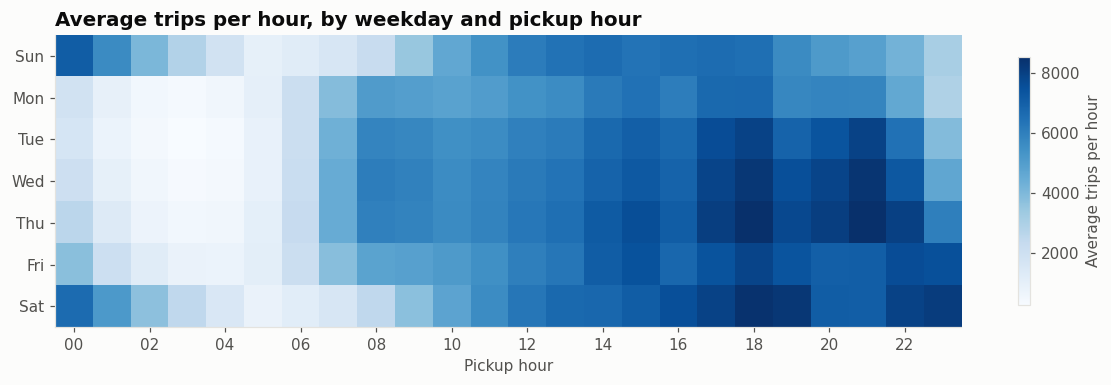

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

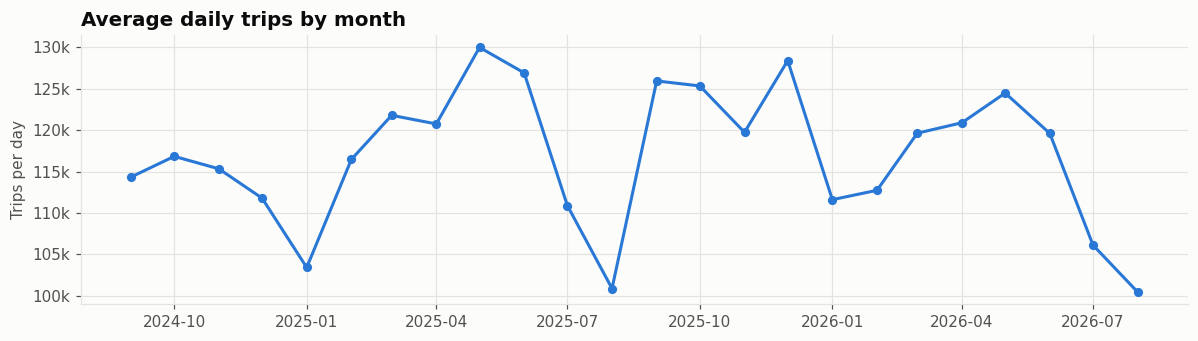

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Busiest slot is Thu 21:00 at 8,521 trips/hour, 33× the quietest (Tue 03:00). Busiest month averages 129,986 trips/day vs. 100,467 in the quietest.


In [2]:
# 2.1 'When': average trips per hour by weekday and hour, plus daily trips by month
hw = q('''
  SELECT pu_dow, pu_hour, COUNT(*) / COUNT(DISTINCT pu_date) AS trips_per_hour
  FROM trips
  GROUP BY 1, 2''')
grid = hw.pivot(index='pu_dow', columns='pu_hour', values='trips_per_hour').reindex(range(7))
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(grid, aspect='auto', cmap='Blues')      # sequential: one hue, light → dark
ax.set_yticks(range(7), DOW)
ax.set_xticks(range(0, 24, 2), [f'{h:02d}' for h in range(0, 24, 2)])
ax.set_xlabel('Pickup hour')
ax.grid(False)
fig.colorbar(im, ax=ax, label="Average trips per hour", shrink=0.85)
ax.set_title('Average trips per hour, by weekday and pickup hour')
save(fig, '01a_hour_weekday')

monthly = q('''
  SELECT DATE_TRUNC('month', pu_date) AS month, COUNT(*) / COUNT(DISTINCT pu_date) AS trips_per_day
  FROM trips
  GROUP BY 1
  ORDER BY 1
  ''')
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(monthly.month, monthly.trips_per_day, marker='o', markersize=5, color=C[0])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
ax.set_ylabel('Trips per day')
ax.set_title('Average daily trips by month')
save(fig, '01b_monthly')

peak = hw.loc[hw.trips_per_hour.idxmax()]
low = hw.loc[hw.trips_per_hour.idxmin()]
holiday = q('''
  SELECT is_holiday, COUNT(*) / COUNT(DISTINCT pu_date) AS per_day
  FROM trips
  WHERE NOT is_weekend
  GROUP BY 1
''')
FINDINGS['when'] = (
    f"Busiest slot is {DOW[int(peak.pu_dow)]} {int(peak.pu_hour):02d}:00 at {peak.trips_per_hour:,.0f} trips/hour, "
    f"{peak.trips_per_hour / low.trips_per_hour:.0f}× the quietest ({DOW[int(low.pu_dow)]} {int(low.pu_hour):02d}:00). "
    + (f"Weekday holidays run {100 * (holiday[True] / holiday[False] - 1):+.0f}% vs. normal weekdays. "
       if True in holiday.index and False in holiday.index else "")
    + (f"Busiest month averages {monthly.trips_per_day.max():,.0f} trips/day vs. {monthly.trips_per_day.min():,.0f} in the quietest."
       if len(monthly) > 1 else ""))
print(FINDINGS['when'])


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

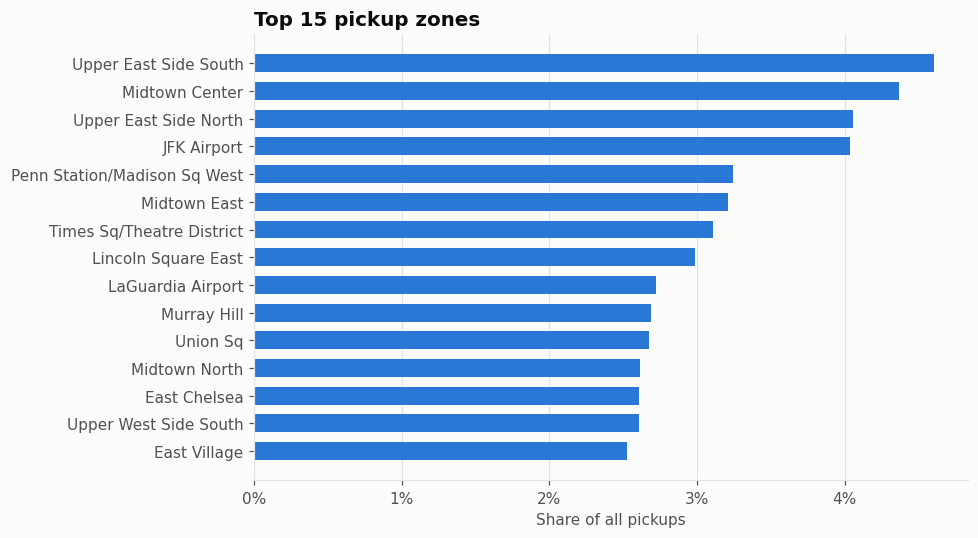

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

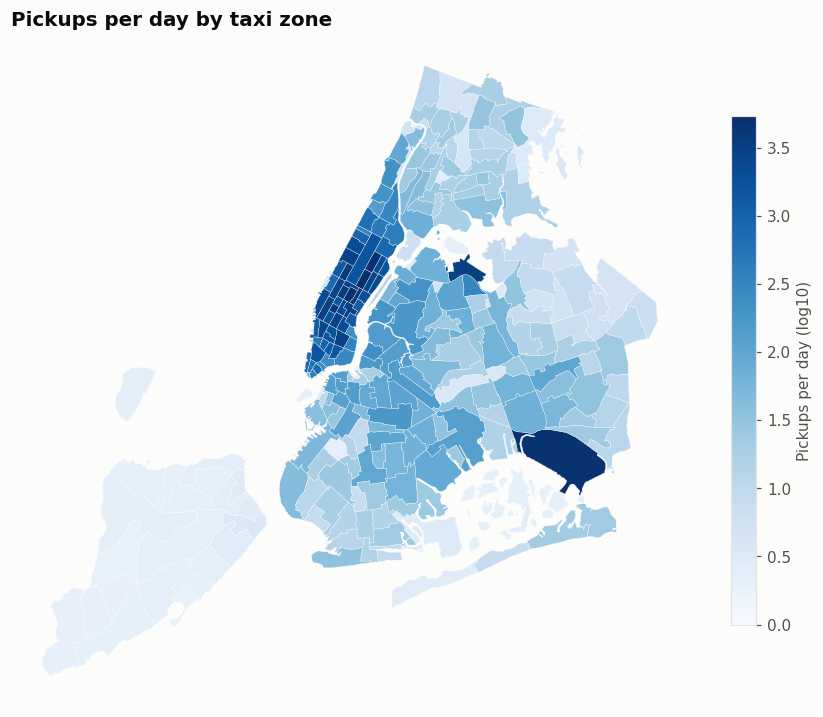

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,route,trips,median_min,median_total
0,Upper East Side South->Upper East Side North,577118,6.8,15.47
1,Upper East Side North->Upper East Side South,491127,7.6,15.95
2,Midtown Center->Upper East Side South,266096,9.2,18.00
3,Upper East Side South->Midtown Center,245348,9.7,17.70
4,Midtown Center->Upper East Side North,215948,13.2,22.75
5,Upper East Side South->Midtown East,204336,8.1,16.75
6,Lincoln Square East->Upper West Side South,201589,5.9,14.84
7,Upper West Side South->Upper West Side North,195292,4.9,13.57
8,Upper West Side South->Lincoln Square East,194652,5.9,14.28
9,Upper East Side North->Midtown Center,187179,14.2,22.49


87% of pickups are in Manhattan. The top 3 zones (Upper East Side South, Midtown Center, Upper East Side North) take 13% of all pickups; the busiest route is Upper East Side South->Upper East Side North (577,118 trips, median 7 min).


In [11]:
# 2.2 'Where': top 15 pickup zones, a map of pickups by zone, and the 10 busiest routes
top = q('''
  SELECT pu_zone AS zone, pu_borough AS borough, COUNT(*) AS trips,
  100.0 * count(*) / sum(count(*)) OVER () AS share
  FROM trips
  GROUP BY 1, 2
  ORDER BY trips DESC
  LIMIT 15
''')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.zone[::-1], top.share[::-1], color=C[0], height=0.65)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis='y', visible=False)
ax.set_xlabel('Share of all pickups')
ax.set_title('Top 15 pickup zones')
save(fig, '02a_top_zones')

# Choropleth: TLC zone shapefile
import geopandas as gpd
shp_zip = BASE / 'raw' / 'taxi_zones.zip'
if not shp_zip.exists():
  urllib.request.urlretrieve("https://d37ci6vzurychx.cloudfront.net/misc/taxi_zones.zip", shp_zip)
shp_dir = BASE / 'raw' / 'taxi_zones'
if not shp_dir.exists():
  zipfile.ZipFile(shp_zip).extractall(shp_dir)
gdf = gpd.read_file(next(shp_dir.rglob('*.shp')))
gdf.columns = [c.lower() for c in gdf.columns]

by_zone = q('''
  SELECT pulocationid AS locationid, COUNT(*) / COUNT(DISTINCT pu_date) AS per_day
  FROM trips
  GROUP BY 1
''')
gmap = gdf.merge(by_zone, on='locationid', how='left').fillna({'per_day': 0})
fig, ax = plt.subplots(figsize=(8, 8))
gmap.plot(column=np.log10(gmap.per_day + 1), cmap='Blues', linewidth=0.2, edgecolor='white', ax=ax,
          legend=True, legend_kwds={'label': 'Pickups per day (log10)', 'shrink': 0.6})
ax.set_axis_off()
ax.set_title('Pickups per day by taxi zone')
save(fig, '02b_pickup_map')

routes = q('''
  SELECT pu_zone || '->' || do_zone AS route, COUNT(*) AS trips,
  ROUND(MEDIAN(duration_min), 1) AS median_min,
  ROUND(MEDIAN(total_amount), 2) AS median_total
  FROM trips
  WHERE pulocationid <> dolocationid
  GROUP BY 1
  ORDER BY trips DESC
  LIMIT 10
''')
display(routes)

top3 = top.head(3)
manhattan = q("SELECT 100.0 * avg((pu_borough = 'Manhattan')::INT) AS pct FROM trips").pct[0]
FINDINGS["where"] = (
    f"{manhattan:.0f}% of pickups are in Manhattan. The top 3 zones ({', '.join(top3.zone)}) take "
    f"{top3.share.sum():.0f}% of all pickups; the busiest route is {routes.route[0]} "
    f"({routes.trips[0]:,} trips, median {routes.median_min[0]:.0f} min).")
print(FINDINGS["where"])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

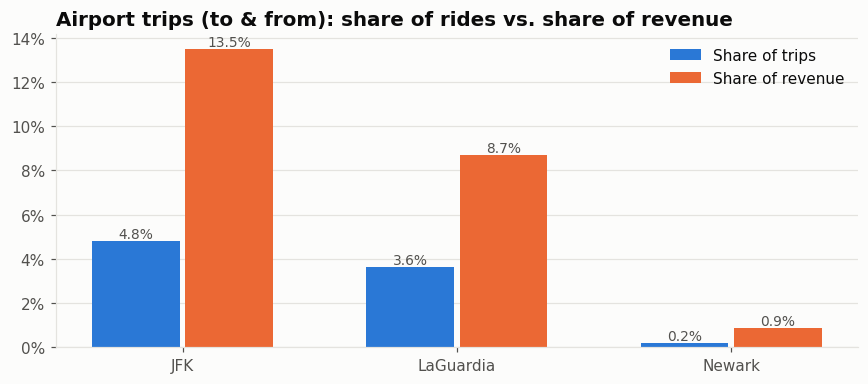

Airport trips are 8.6% of rides but 23.1% of revenue (2.7× their share). 56% of JFK trips use the flat fare (rate code 2); median JFK total is $89 vs. $21 for non-airport trips.


In [4]:
# 2.3 AIRPORTS (zones 1, 132, 138)
air = q('''
  SELECT CASE WHEN 132 IN (pulocationid, dolocationid) THEN 'JFK'
              WHEN 138 IN (pulocationid, dolocationid) THEN 'LaGuardia'
              WHEN 1   IN (pulocationid, dolocationid) THEN 'Newark'
              ELSE 'Non-airport' END AS segment,
         100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS trip_share,
         100.0 * SUM(total_amount) / SUM(SUM(total_amount)) OVER () AS revenue_share,
         100.0 * AVG((ratecodeid = 2)::INT) AS flat_fare_pct,
         MEDIAN(total_amount) AS median_total
  FROM trips
  GROUP BY 1
''').set_index('segment').reindex(['JFK', 'LaGuardia', 'Newark', 'Non-airport']).dropna()
airports = air.drop(labels='Non-airport',errors='ignore')
x = np.arange(len(airports))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(x - 0.17, airports.trip_share, width=0.32, color=C[0], label="Share of trips")
ax.bar(x + 0.17, airports.revenue_share, width=0.32, color=C[1], label="Share of revenue")
for xi, (t, r) in enumerate(zip(airports.trip_share, airports.revenue_share)):
    ax.text(xi - 0.17, t, f"{t:.1f}%", ha="center", va="bottom", fontsize=9, color=INK2)
    ax.text(xi + 0.17, r, f"{r:.1f}%", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_xticks(x, airports.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
ax.set_title("Airport trips (to & from): share of rides vs. share of revenue")
save(fig, "03_airports")

a_trips, a_rev = airports.trip_share.sum(), airports.revenue_share.sum()
FINDINGS["airports"] = (
    f"Airport trips are {a_trips:.1f}% of rides but {a_rev:.1f}% of revenue ({a_rev / a_trips:.1f}× their share). "
    + (f"{airports.flat_fare_pct.get('JFK', 0):.0f}% of JFK trips use the flat fare (rate code 2); "
       f"median JFK total is ${airports.median_total.get('JFK', 0):.0f} vs. "
       f"${air.median_total.get('Non-airport', 0):.0f} for non-airport trips." if "JFK" in airports.index else ""))
print(FINDINGS["airports"])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

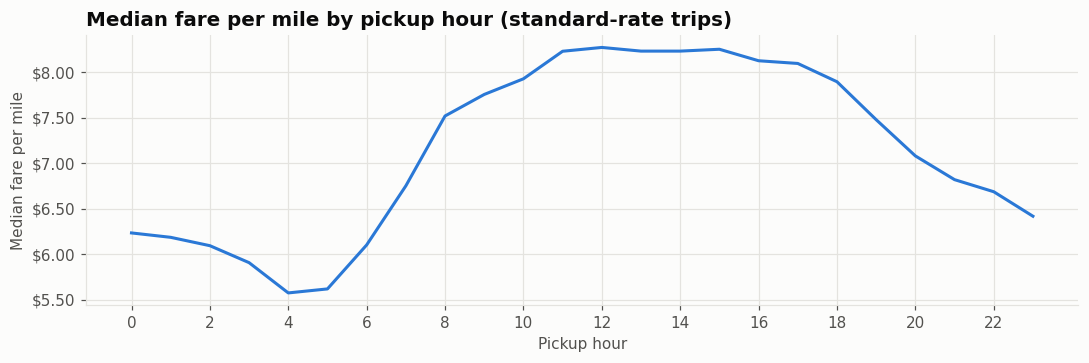

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

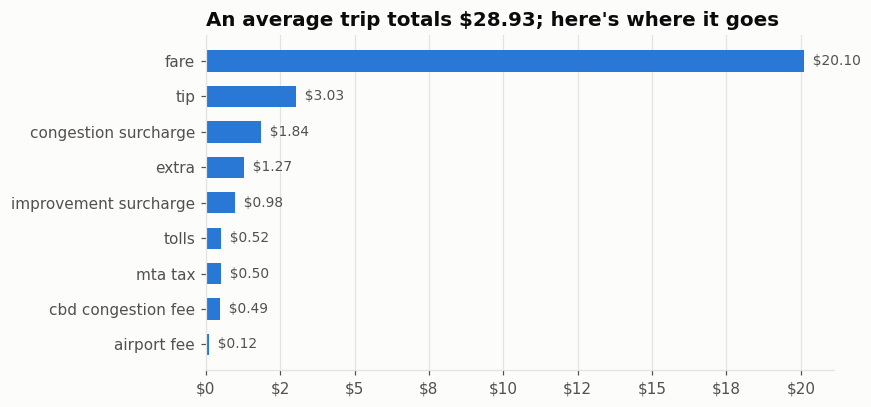

Median fare per mile peaks at $8.27 (12:00) vs. $5.58 at its low (04:00). The meter fare is 69% of the average $28.93 total; surcharges and fees add $5.72.


In [5]:
# 2.4 Fares
fpm = q('''
  SELECT pu_hour, MEDIAN(fare_amount / trip_distance) AS fare_per_mile,
    MEDIAN(fare_amount / duration_min) AS fare_per_min
  FROM trips
  WHERE ratecodeid = 1 AND trip_distance >= 0.5
  GROUP BY 1
  ORDER BY 1
''')
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(fpm.pu_hour, fpm.fare_per_mile, color=C[0])
ax.set_xticks(range(0, 24, 2))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:.2f}"))
ax.set_xlabel("Pickup hour")
ax.set_ylabel("Median fare per mile")
ax.set_title("Median fare per mile by pickup hour (standard-rate trips)")
save(fig, "04a_fare_per_mile")

parts = ["fare_amount", "tip_amount", "congestion_surcharge", "extra", "tolls_amount",
         "airport_fee", "improvement_surcharge", "mta_tax", "cbd_congestion_fee"]

comp = q(f"SELECT {', '.join(f'AVG({p}) AS {p}' for p in parts)}, AVG(total_amount) AS total FROM trips").iloc[0]
comp_parts = comp[parts].sort_values()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh([p.replace("_amount", "").replace("_", " ") for p in comp_parts.index], comp_parts.values,
        color=C[0], height=0.6)
for i, v in enumerate(comp_parts.values):
    ax.text(v, i, f"  ${v:.2f}", va="center", fontsize=9, color=INK2)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:.0f}"))
ax.set_title(f"An average trip totals ${comp.total:.2f}; here's where it goes")
save(fig, "04b_fare_components")

FINDINGS["fares"] = (
    f"Median fare per mile peaks at ${fpm.fare_per_mile.max():.2f} ({int(fpm.loc[fpm.fare_per_mile.idxmax(), 'pu_hour']):02d}:00) "
    f"vs. ${fpm.fare_per_mile.min():.2f} at its low ({int(fpm.loc[fpm.fare_per_mile.idxmin(), 'pu_hour']):02d}:00). "
    f"The meter fare is {100 * comp.fare_amount / comp.total:.0f}% of the average ${comp.total:.2f} total; "
    f"surcharges and fees add ${comp[parts].sum() - comp.fare_amount - comp.tip_amount:.2f}.")
print(FINDINGS["fares"])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

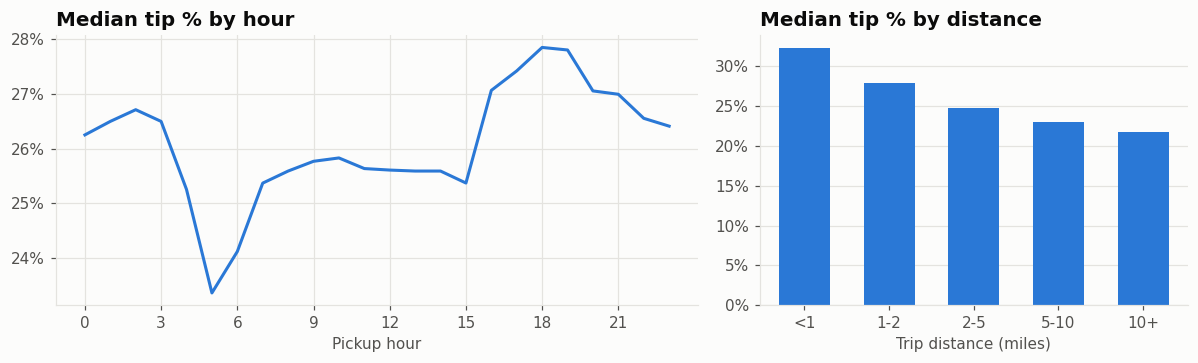

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

69% of trips are paid by card. Among them the median tip is 26% of fare, ranging 22–32% across distance bands (highest for <1 mi); 7% of card trips leave no tip.


In [6]:
# 2.5 Tips
tip_hour = q('''
  SELECT pu_hour, MEDIAN(tip_pct) AS median_tip,
    100.0 * AVG((tip_amount)::INT) AS no_tip_pct
  FROM trips
  WHERE payment_type = 1
  GROUP BY 1
  ORDER BY 1
''')
tip_dist = q('''
  SELECT CASE WHEN trip_distance < 1 THEN '<1'
              WHEN trip_distance < 2 THEN '1-2'
              WHEN trip_distance < 5 THEN '2-5'
              WHEN trip_distance < 10 THEN '5-10'
              ELSE '10+' END AS miles,
    MIN(trip_distance) AS sort_key, MEDIAN(tip_pct) AS median_tip, COUNT(*) AS trips
  FROM trips
  WHERE payment_type = 1
  GROUP BY 1
  ORDER BY sort_key
''')
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [3, 2]})
a1.plot(tip_hour.pu_hour, tip_hour.median_tip, color=C[0])
a1.set_xticks(range(0, 24, 3))
a1.set_xlabel("Pickup hour")
a1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
a1.set_title("Median tip % by hour")
a2.bar(tip_dist.miles, tip_dist.median_tip, color=C[0], width=0.6)
a2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
a2.grid(axis="x", visible=False)
a2.set_xlabel("Trip distance (miles)")
a2.set_title("Median tip % by distance")
save(fig, "05_tips")

card = q('''
  SELECT 100.0 * AVG((payment_type = 1)::INT) AS card_pct
  FROM trips
''').card_pct[0]
no_tip = q('''
  SELECT 100.0 * AVG((tip_amount = 0)::INT) AS t
  FROM trips
  WHERE payment_type = 1
''').t[0]
FINDINGS["tips"] = (
    f"{card:.0f}% of trips are paid by card. Among them the median tip is {tip_hour.median_tip.median():.0f}% of fare, "
    f"ranging {tip_dist.median_tip.min():.0f}–{tip_dist.median_tip.max():.0f}% across distance bands "
    f"(highest for {tip_dist.loc[tip_dist.median_tip.idxmax(), 'miles']} mi); {no_tip:.0f}% of card trips leave no tip.")
print(FINDINGS["tips"])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

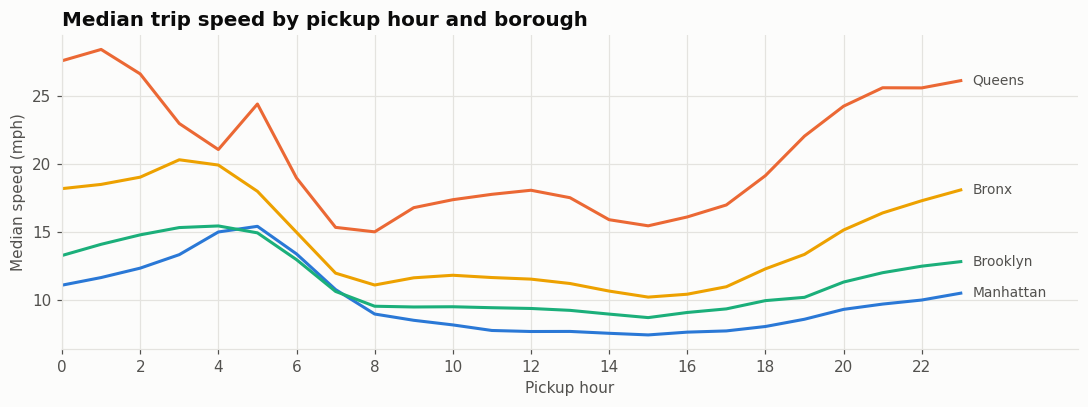

Manhattan trips average 7.5 mph at the slowest hour (15:00) and 15.4 mph at the fastest (05:00).


In [7]:
# 2.6 Speed
speed = q('''
  SELECT pu_borough AS borough, pu_hour, MEDIAN(speed_mph) AS mph, COUNT(*) AS trips
  FROM trips
  WHERE pu_borough IN ('Manhattan', 'Queens', 'Brooklyn', 'Bronx')
  GROUP BY 1,2
  ORDER BY 1,2
''')
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, b in enumerate(["Manhattan", "Queens", "Brooklyn", "Bronx"]):   # fixed order → fixed colour
    s = speed[speed.borough == b]
    if len(s):
        ax.plot(s.pu_hour, s.mph, color=C[i], label=b)
        ax.text(23.3, s.mph.iloc[-1], b, color=INK2, fontsize=9, va="center")
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(0, 26)
ax.set_xlabel("Pickup hour")
ax.set_ylabel("Median speed (mph)")
# ax.legend(loc="upper center", ncol=4)
ax.set_title("Median trip speed by pickup hour and borough")
save(fig, "06_speed")

m = speed[speed.borough == "Manhattan"].set_index("pu_hour").mph
FINDINGS["speed"] = (
    f"Manhattan trips average {m.min():.1f} mph at the slowest hour ({int(m.idxmin()):02d}:00) and "
    f"{m.max():.1f} mph at the fastest ({int(m.idxmax()):02d}:00)." if len(m) else "No Manhattan trips found.")
print(FINDINGS["speed"])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

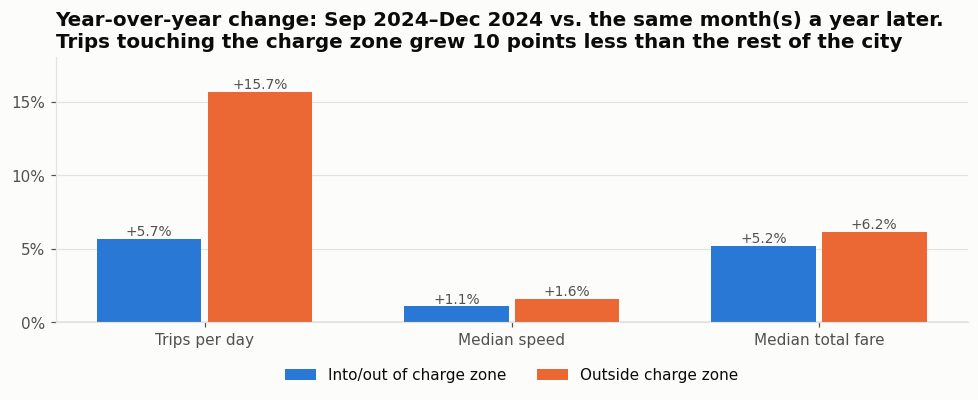

Comparing 4 month(s) a year apart, trips touching the charge zone changed +5.7% in volume, +1.1% in median speed, and +5.2% in median total fare; trips outside the zone changed +15.7% in volume.


In [8]:
# 2.7 Congestion pricing
pairs = q('''
  WITH m AS (SELECT DISTINCT date_trunc('month', pu_date) AS month FROM trips)
  SELECT a.month AS before, b.month AS after
  FROM m a
  JOIN m b
  ON b.month = a.month + INTERVAL 1 YEAR
  WHERE a.month < DATE '2025-01-01'
''')
if pairs.empty:
  FINDINGS['congestion'] = "Skipped: needs at least one 2024 month and the same month in 2025 (set DEV_MODE=False in Phase 1)."
else:
  befores = ", ".join(f"DATE '{d:%Y-%m-%d}'" for d in pairs.before)
  afters = ", ".join(f"DATE '{d:%Y-%m-%d}'" for d in pairs.after)
  cp = q(f'''
    SELECT CASE WHEN touches_cbd THEN 'Into/out of charge zone' ELSE 'Outside charge zone' END AS segment,
           CASE WHEN DATE_TRUNC('month', pu_date) IN ({befores}) THEN 'before' ELSE 'after' END AS period,
      COUNT(*) / COUNT(DISTINCT pu_date) AS trips_per_day,
      MEDIAN(speed_mph) AS mph, MEDIAN(total_amount) AS total
    FROM trips
    WHERE DATE_TRUNC('month', pu_date) IN ({befores}, {afters})
    GROUP BY 1, 2
  ''')
  w = cp.pivot(index="segment", columns="period")
  change = pd.DataFrame({
      'Trips per day': 100.0 * (w.trips_per_day.after / w.trips_per_day.before - 1),
      'Median speed': 100.0 * (w.mph.after / w.mph.before - 1),
      'Median total fare': 100.0 * (w.total.after / w.total.before - 1)
  })
  x = np.arange(len(change.columns))
  fig, ax = plt.subplots(figsize=(9, 3.8))
  for i, seg in enumerate(["Into/out of charge zone", "Outside charge zone"]):
      if seg in change.index:
          vals = change.loc[seg].values
          ax.bar(x + (i - 0.5) * 0.36, vals, width=0.34, color=C[i], label=seg)
          for xi, v in zip(x, vals):
              ax.text(xi + (i - 0.5) * 0.36, v, f"{v:+.1f}%", ha="center",
                      va="bottom" if v >= 0 else "top", fontsize=9, color=INK2)
  ax.axhline(0, color=INK2, linewidth=0.8)
  ax.set_xticks(x, change.columns)
  ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
  ax.grid(axis="x", visible=False)
  ax.margins(y=0.15)
  ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
  rng = (f"{pairs.before.min():%b %Y}" if len(pairs) == 1
          else f"{pairs.before.min():%b %Y}–{pairs.before.max():%b %Y}")
  ax.set_title(f"Year-over-year change: {rng} vs. the same month(s) a year later.\nTrips touching the charge zone grew 10 points less than the rest of the city")
  ax.yaxis.set_major_locator(mtick.MultipleLocator(5))
  save(fig, "07_congestion_pricing")

  cz = change.loc["Into/out of charge zone"]
  FINDINGS["congestion"] = (
      f"Comparing {len(pairs)} month(s) a year apart, trips touching the charge zone changed {cz['Trips per day']:+.1f}% "
      f"in volume, {cz['Median speed']:+.1f}% in median speed, and {cz['Median total fare']:+.1f}% in median total fare"
      + (f"; trips outside the zone changed {change.loc['Outside charge zone', 'Trips per day']:+.1f}% in volume."
          if "Outside charge zone" in change.index else "."))
print(FINDINGS["congestion"])


In [9]:
# Save FINDINGS
md = '# Phase 2 findings\n\n' + '\n'.join(f'- **{k.title()}:** {v}' for k, v in FINDINGS.items())
(BASE / 'findings.md').write_text(md)
print(md)

# Phase 2 findings

- **When:** Busiest slot is Thu 21:00 at 8,521 trips/hour, 33× the quietest (Tue 03:00). Busiest month averages 129,986 trips/day vs. 100,467 in the quietest.
- **Where:** 87% of pickups are in Manhattan. The top 3 zones (Upper East Side South, Midtown Center, Upper East Side North) take 13% of all pickups; the busiest route is Upper East Side South->Upper East Side North (577,118 trips, median 7 min).
- **Airports:** Airport trips are 8.6% of rides but 23.1% of revenue (2.7× their share). 56% of JFK trips use the flat fare (rate code 2); median JFK total is $89 vs. $21 for non-airport trips.
- **Fares:** Median fare per mile peaks at $8.27 (12:00) vs. $5.58 at its low (04:00). The meter fare is 69% of the average $28.93 total; surcharges and fees add $5.72.
- **Tips:** 69% of trips are paid by card. Among them the median tip is 26% of fare, ranging 22–32% across distance bands (highest for <1 mi); 7% of card trips leave no tip.
- **Speed:** Manhattan trips average 